# California Housing Price Prediction

## 1.Project Overview

The objective of this project is to explore the California Housing dataset and develop regression models to predict median house values using demographic and geographic features.

## 2.Objectives

- Perform exploratory data analysis (EDA).
- Investigate missing values, duplicates, distributions, and potential outliers.
- Examine relationships between predictors and the target variable.
- Build and evaluate regression models using appropriate validation techniques.
- Compare Linear Regression, Polynomial Regression, Ridge, Lasso, and Elastic Net.
- Document the findings in a reproducible Jupyter notebook.

## 3.Dataset

- **Source:** Scikit-learn California Housing dataset
- **Observations:** 20,640
- **Columns:** 9
- **Target:** `MedHouseVal`
- **Predictors:** 8 demographic and geographic features

**Note:** The target represents median house value at the district level, not the price of an individual house. The target is expressed in units of $100,000.

In [103]:

import sklearn
import pandas as pd
import numpy as np

print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


Scikit-learn: 1.7.1
Pandas: 2.3.1
NumPy: 2.3.1


In [104]:

# Load the California Housing dataset
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

# Create a DataFrame containing features and target
df = housing.frame


In [105]:
print(f"Dataset loaded successfully: {df.shape[0]:,} rows and {df.shape[1]} columns.")

Dataset loaded successfully: 20,640 rows and 9 columns.


## 4. Initial Dataset Inspection

Inspect the dataset's sample records, structure, column data types, and numerical summaries to understand its contents before performing data-quality checks and exploratory data analysis.

In [106]:

# Display the first and last five rows
display(df.head())
display(df.tail())


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [107]:

# Inspect column names, data types, and non-null counts
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [108]:

# Summarize numerical columns
df.describe()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## 5. Data Quality Checks

Check for missing values and completely duplicated rows to assess the dataset's basic data quality before further analysis.

In [109]:

# Count missing values in each column
df.isnull().sum()


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [110]:

# Count rows that are exact duplicates across all columns
df.duplicated().sum()


np.int64(0)

## 6. Target Variable Investigation

Examine the minimum, maximum, and median of `MedHouseVal`, and count observations at the maximum value to understand the target's range and potential upper-bound concentration.

In [111]:

# Minimum, maximum, and median target values
print("Minimum:", df["MedHouseVal"].min())
print("Maximum:", df["MedHouseVal"].max())
print("Median:", df["MedHouseVal"].median())


Minimum: 0.14999
Maximum: 5.00001
Median: 1.797


In [112]:

max_value = df["MedHouseVal"].max()
max_count = (df["MedHouseVal"] == max_value).sum()

print("Observations at maximum:", max_count)
print("Percentage of dataset:", round(max_count / len(df) * 100, 2), "%")


Observations at maximum: 965
Percentage of dataset: 4.68 %


## 7. Exploratory Data Analysis (EDA)

### 7.1 Distribution of the Target Variable

Visualize the distribution of `MedHouseVal` using a histogram to understand the range, frequency, and concentration of median house values across California districts.

This plot can help identify skewness, clustering, and any unusual patterns, including a possible concentration of observations near the target's upper limit.

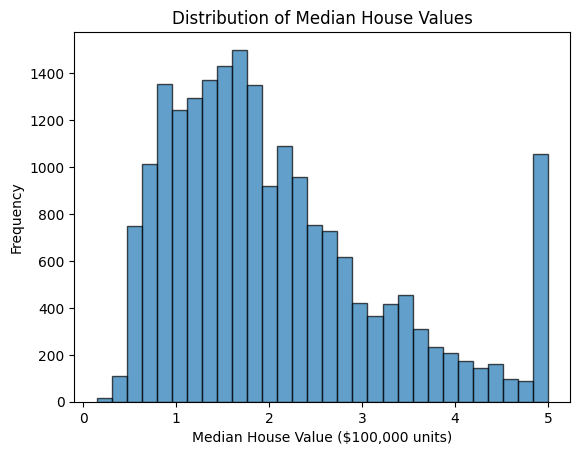

In [113]:

import matplotlib.pyplot as plt

plt.hist(df["MedHouseVal"], bins=30, edgecolor="black", alpha=0.7)

plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Frequency")
plt.title("Distribution of Median House Values")

plt.show()


### 7.2 Distribution of Selected Features

Visualize the distributions of `AveRooms`, `AveBedrms`, and `AveOccup` using histograms to examine their spread, skewness, and potential extreme values.

These features describe average rooms per household, average bedrooms per household, and average household occupancy, respectively.

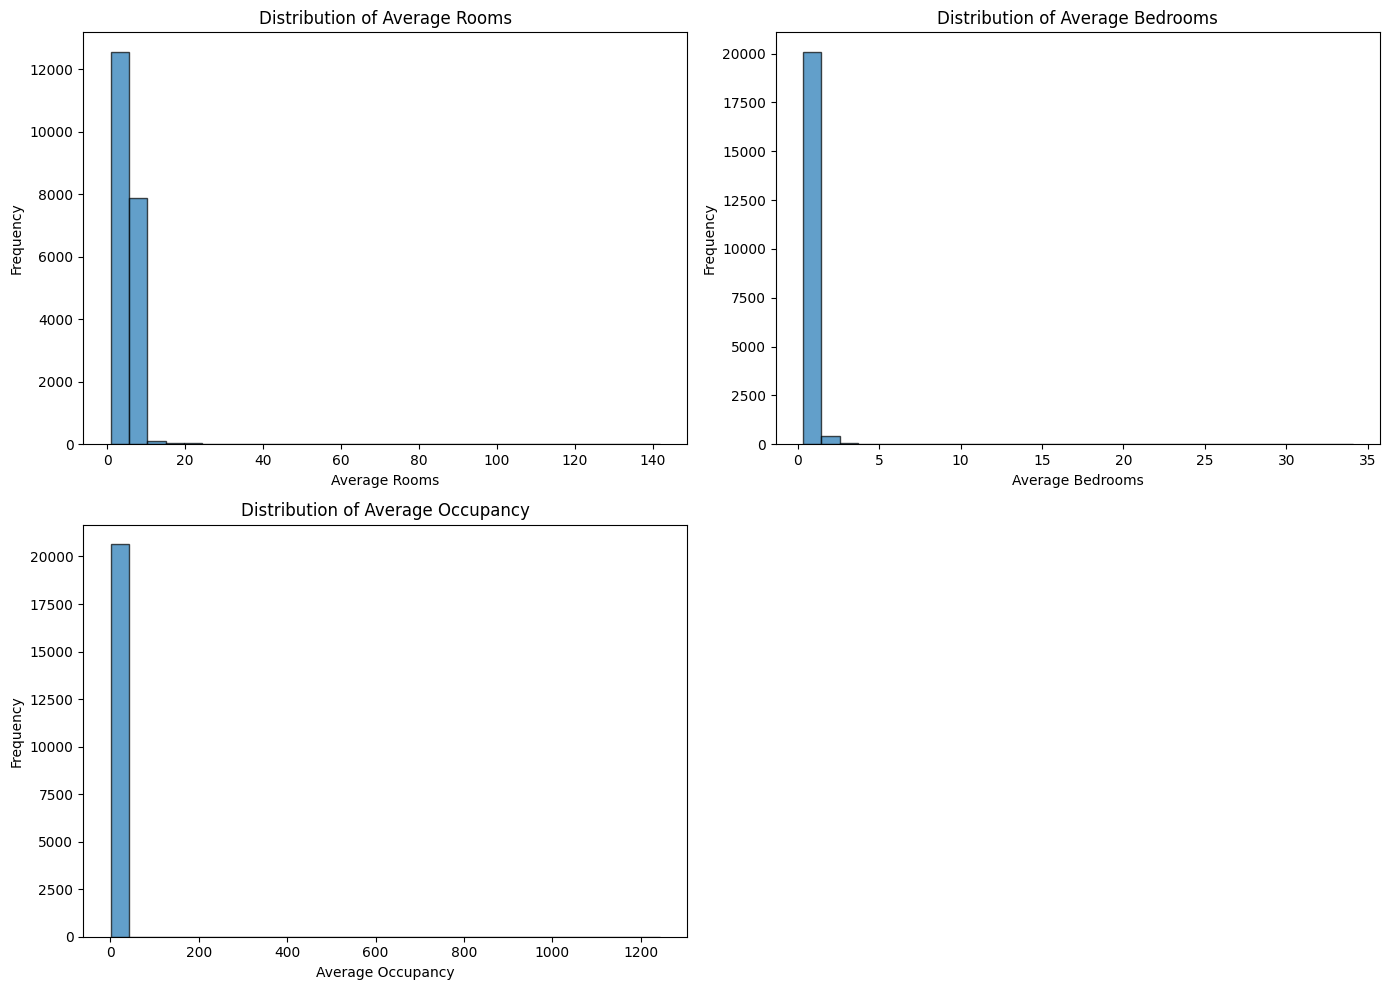

In [114]:

plt.figure(figsize=(14, 10))

# Average rooms
plt.subplot(2, 2, 1)
plt.hist(df["AveRooms"], bins=30, edgecolor="black", alpha=0.7)
plt.title("Distribution of Average Rooms")
plt.xlabel("Average Rooms")
plt.ylabel("Frequency")

# Average bedrooms
plt.subplot(2, 2, 2)
plt.hist(df["AveBedrms"], bins=30, edgecolor="black", alpha=0.7)
plt.title("Distribution of Average Bedrooms")
plt.xlabel("Average Bedrooms")
plt.ylabel("Frequency")

# Average occupancy
plt.subplot(2, 2, 3)
plt.hist(df["AveOccup"], bins=30, edgecolor="black", alpha=0.7)
plt.title("Distribution of Average Occupancy")
plt.xlabel("Average Occupancy")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


### 7.3 IQR-Based Outlier Investigation of the Target

Use the Interquartile Range (IQR) method to identify observations in `MedHouseVal` that fall outside the conventional 1.5 × IQR fences.

- **Q1:** 25th percentile
- **Q3:** 75th percentile
- **IQR:** Q3 − Q1
- **Lower bound:** Q1 − 1.5 × IQR
- **Upper bound:** Q3 + 1.5 × IQR

Observations outside these bounds are flagged as potential outliers. These statistical flags do not necessarily indicate incorrect data, so observations will not be removed automatically.

In [115]:

# Calculate quartiles and IQR
min_val, q1, median, q3, max_val = df["MedHouseVal"].quantile(
    [0, 0.25, 0.5, 0.75, 1]
)

iqr = q3 - q1

# Calculate IQR bounds
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Display results
print("Q1:", q1)
print("Median:", median)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

# Count observations outside the IQR bounds
outlier_count = (
    (df["MedHouseVal"] < lower_bound) |
    (df["MedHouseVal"] > upper_bound)
).sum()

print("Potential outliers:", outlier_count)


Q1: 1.196
Median: 1.797
Q3: 2.6472499999999997
IQR: 1.4512499999999997
Lower bound: -0.9808749999999995
Upper bound: 4.824124999999999
Potential outliers: 1071


### 7.4 IQR-Based Outlier Analysis Across Selected Columns

Apply the Interquartile Range (IQR) method to selected numerical features and the target variable to identify observations outside the conventional 1.5 × IQR bounds.

This comparison helps us understand how extreme values are distributed across different variables. An observation flagged as an outlier is not necessarily erroneous, so these results will be used for investigation rather than automatic removal.

In [116]:

features_to_analyze = [
    "AveRooms",
    "AveBedrms",
    "AveOccup",
    "MedHouseVal"
]

print("IQR Outlier Analysis Summary")
print("=" * 40)

for col in features_to_analyze:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    label = "Target" if col == "MedHouseVal" else "Feature"

    print(f"\n[{label}: {col}]")
    print(f"  Q1: {q1:.4f}")
    print(f"  Q3: {q3:.4f}")
    print(f"  IQR: {iqr:.4f}")
    print(f"  Lower bound: {lower_bound:.4f}")
    print(f"  Upper bound: {upper_bound:.4f}")
    print(f"  Potential outliers: {outlier_count:,}")


IQR Outlier Analysis Summary

[Feature: AveRooms]
  Q1: 4.4407
  Q3: 6.0524
  IQR: 1.6117
  Lower bound: 2.0232
  Upper bound: 8.4699
  Potential outliers: 511

[Feature: AveBedrms]
  Q1: 1.0061
  Q3: 1.0995
  IQR: 0.0934
  Lower bound: 0.8659
  Upper bound: 1.2397
  Potential outliers: 1,424

[Feature: AveOccup]
  Q1: 2.4297
  Q3: 3.2823
  IQR: 0.8525
  Lower bound: 1.1510
  Upper bound: 4.5610
  Potential outliers: 711

[Target: MedHouseVal]
  Q1: 1.1960
  Q3: 2.6472
  IQR: 1.4512
  Lower bound: -0.9809
  Upper bound: 4.8241
  Potential outliers: 1,071


### 7.5 Correlation Analysis Using a Heatmap

Calculate the pairwise Pearson correlation coefficients between numerical variables and visualize them using a heatmap.

Correlation analysis helps identify linear relationships between features and the target variable, `MedHouseVal`. It can also reveal relationships between predictors that may be relevant when building regression models.

**Note:** Correlation indicates association, not causation, and may not capture nonlinear relationships.

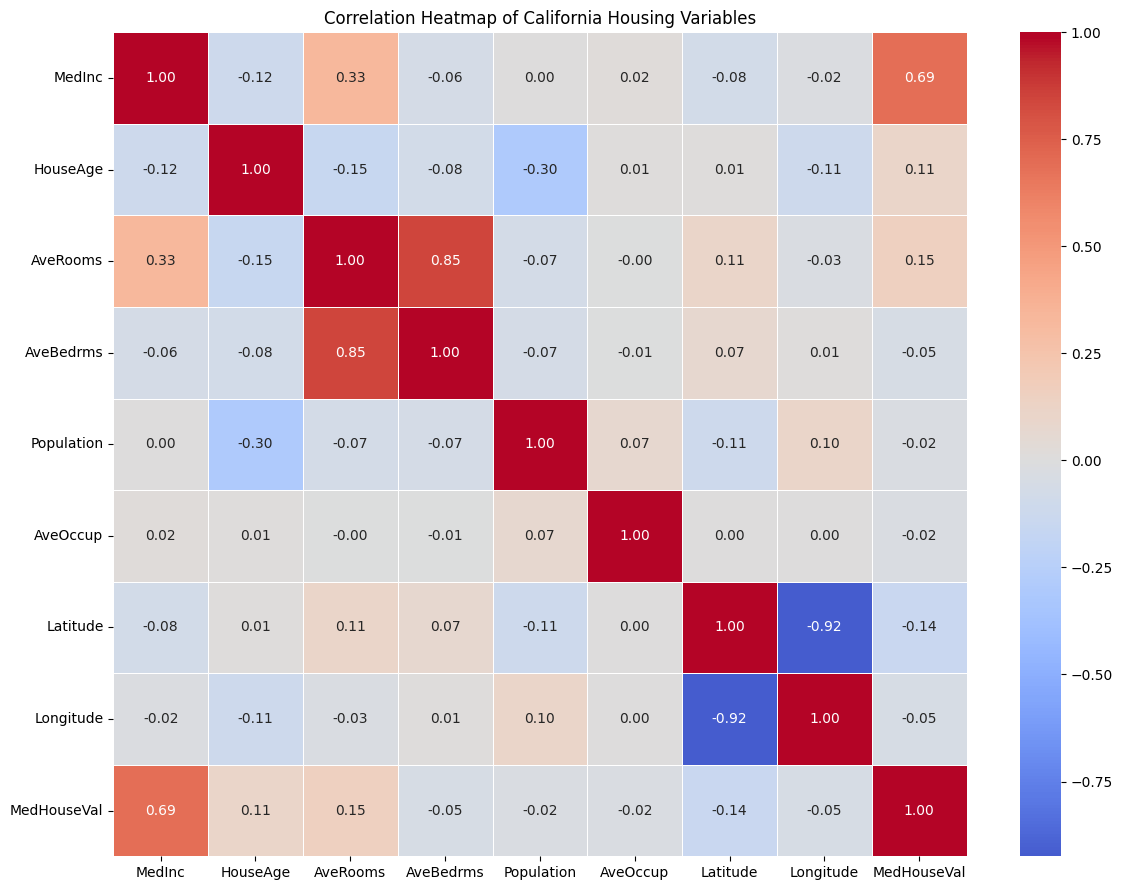

In [117]:

import seaborn as sns

corr = df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of California Housing Variables")
plt.tight_layout()
plt.show()


### 7.6 Identifying the Strongest Correlations with the Target

Examine the correlation coefficients between `MedHouseVal` and each predictor to identify the strongest positive and negative linear relationships.

This helps identify potentially informative features for regression modelling. However, correlation alone does not establish causation or determine a feature's predictive usefulness in every model.

In [118]:

# Correlations with the target, excluding the target's self-correlation
target_corr = corr["MedHouseVal"].drop("MedHouseVal")

strongest_positive = target_corr.idxmax()
strongest_negative = target_corr.idxmin()

print(
    f"Strongest positive correlation: "
    f"{strongest_positive} ({target_corr[strongest_positive]:.4f})"
)

print(
    f"Strongest negative correlation: "
    f"{strongest_negative} ({target_corr[strongest_negative]:.4f})"
)


Strongest positive correlation: MedInc (0.6881)
Strongest negative correlation: Latitude (-0.1442)


### 7.7 Relationship Between Median Income and Median House Value

Investigate the relationship between `MedInc` and `MedHouseVal` using a scatter plot. `MedInc` has the strongest positive individual linear correlation with the target among the available predictors.

**Observations:**

- **Relationship:** House values generally increase with median income, although the points are scattered and the pattern is not perfectly linear.
- **Spread:** The vertical spread of house values varies across income levels, suggesting that income alone does not fully explain differences in median house values.
- **Ceiling effect:** A clear concentration of observations appears near `MedHouseVal = 5.0`, consistent with the dataset's upper target-value cap.

**Conclusion:** Median income is an informative predictor, but the scatter plot suggests that additional features and potentially nonlinear relationships may help explain house values.

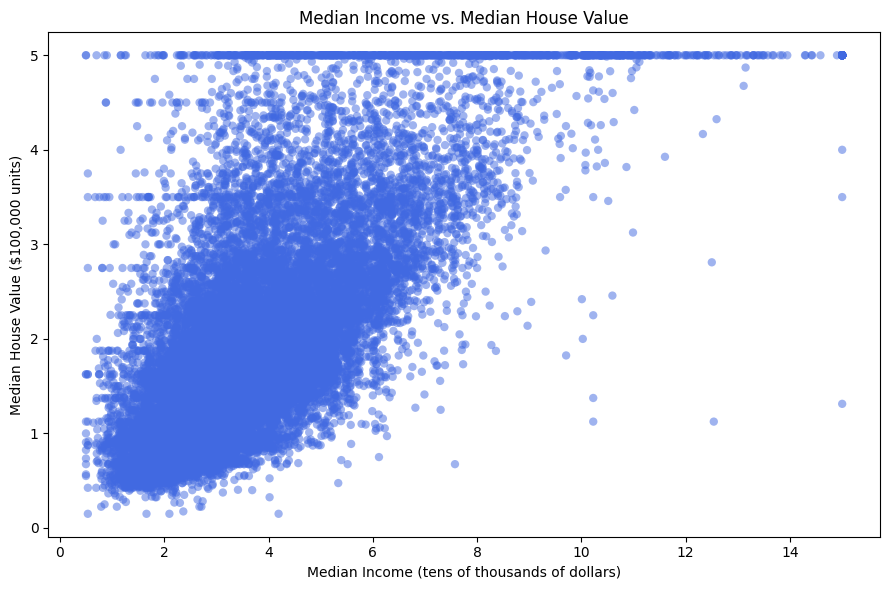

In [119]:

plt.figure(figsize=(9, 6))

plt.scatter(
    df["MedInc"],
    df["MedHouseVal"],
    alpha=0.5,
    color="royalblue",
    edgecolor="none"
)

plt.xlabel("Median Income (tens of thousands of dollars)")
plt.ylabel("Median House Value ($100,000 units)")
plt.title("Median Income vs. Median House Value")

plt.tight_layout()
plt.show()


### 7.8 Geographic Distribution of Median House Values

Explore the spatial distribution of `MedHouseVal` using longitude and latitude, with point colours representing median house values.

This visualization helps investigate whether higher-value districts cluster geographically and whether location may capture patterns that a simple linear correlation cannot fully describe.

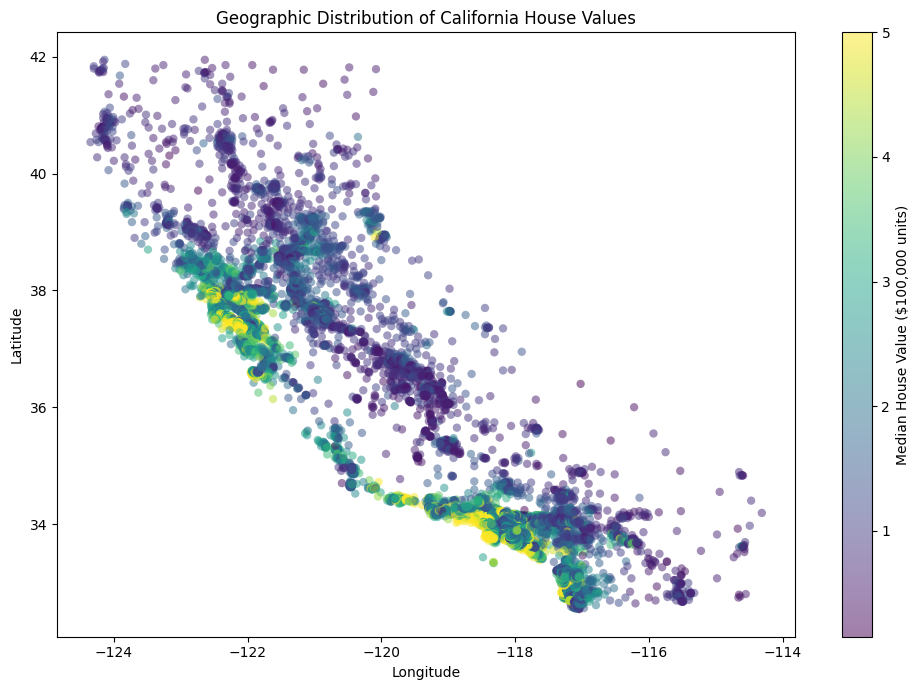

In [120]:

plt.figure(figsize=(10, 7))

plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["MedHouseVal"],
    cmap="viridis",
    alpha=0.5,
    edgecolors="none"
)

plt.colorbar(label="Median House Value ($100,000 units)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of California House Values")

plt.tight_layout()
plt.show()


**Observations:**

1. **Geographic clustering:** Higher-value districts appear to cluster in certain coastal and metropolitan areas, rather than being distributed uniformly across California.
2. **Complex relationship:** House values show spatial patterns, but the relationship with latitude and longitude is not a simple straight-line relationship.
3. **Why location matters:** Geographic coordinates can indirectly capture differences in local housing demand, accessibility, amenities, employment opportunities, and housing supply. These are plausible explanations for spatial patterns, not causal conclusions established by this plot alone.

**Conclusion:** Geographic features may provide useful predictive information because housing values vary across locations. Their relationship with the target may be nonlinear and may interact with other features.

## 8. Feature and Target Separation

Separate the dataset into predictor variables (`X`) and the target variable (`y`) before building regression models.

- **Independent variables (`X`):** Eight demographic and geographic features used to predict median house values.
- **Dependent variable (`y`):** `MedHouseVal`, representing the district-level median house value.

The target is kept separate from the predictors to prevent it from being inadvertently used as an input feature during model training.

In [121]:

# Separate predictors and target
X = df[
    [
        "MedInc",
        "HouseAge",
        "AveRooms",
        "AveBedrms",
        "Population",
        "AveOccup",
        "Latitude",
        "Longitude"
    ]
]

y = df["MedHouseVal"]

# Verify the shapes and feature names
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Features:", X.columns.tolist())
print("Target:", y.name)


Feature matrix shape: (20640, 8)
Target vector shape: (20640,)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: MedHouseVal


## 9. Train-Test Split

Split the dataset into training and testing sets using `train_test_split` from scikit-learn.

- **Training set (80%):** Used to train the regression models.
- **Testing set (20%):** Reserved for evaluating model performance on unseen observations.
- **`random_state=42`:** Ensures reproducibility by producing the same split when the code is rerun with the same data and settings.

The test set will remain separate during model training and model selection to provide a fair final evaluation.

In [122]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


In [123]:

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


## 10. Feature Scaling Using StandardScaler

Standardize the predictor variables using `StandardScaler` so that each feature has approximately zero mean and unit variance.

This is useful because our features have different scales. For example, `Population` can have much larger numerical values than `HouseAge`.

**Important:** Fit the scaler only on the training features, then use the fitted scaler to transform the testing features. This prevents information from the test set from influencing the scaling parameters.

The target variable, `y`, will remain unscaled for now so that predictions and evaluation metrics remain in the original target units.

In [124]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [125]:

print("Scaled training features:", X_train_scaled.shape)
print("Scaled testing features:", X_test_scaled.shape)

print("Training feature means (first 3):",
      X_train_scaled.mean(axis=0)[:3])

print("Training feature standard deviations (first 3):",
      X_train_scaled.std(axis=0)[:3])


Scaled training features: (16512, 8)
Scaled testing features: (4128, 8)
Training feature means (first 3): [-6.41175313e-17 -1.67824411e-17  1.79012705e-16]
Training feature standard deviations (first 3): [1. 1. 1.]


## 11. Baseline Model — Multiple Linear Regression

Train a Multiple Linear Regression model using the eight predictor variables to estimate `MedHouseVal`.

The model learns a linear relationship between the predictors and the target. This baseline will help us evaluate how effectively a simple linear model captures patterns in the California Housing dataset.

The model will be fitted on the training data, while the test data remains unseen until evaluation.

**Note:** The target variable remains in its original units, so predictions will also be expressed in units of $100,000.

In [126]:

from sklearn.linear_model import LinearRegression

regression = LinearRegression()
regression.fit(X_train_scaled, y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [127]:
print("Intercept:", regression.intercept_)
print("Number of coefficients:", len(regression.coef_))

Intercept: 2.071946937378881
Number of coefficients: 8



## 12. Baseline Model Evaluation

Evaluate the baseline Multiple Linear Regression model using
5-fold cross-validation on the training set.

Out-of-fold predictions are used to calculate evaluation metrics,
while the held-out test set remains reserved for final evaluation
in Section 15.


In [128]:

from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Baseline pipeline
baseline_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Generate out-of-fold predictions using training data only
y_train_oof_pred = cross_val_predict(
    baseline_pipeline,
    X_train,
    y_train,
    cv=5
)

# Calculate out-of-fold evaluation metrics
mae = mean_absolute_error(y_train, y_train_oof_pred)
mse = mean_squared_error(y_train, y_train_oof_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_train_oof_pred)

print(f"5-Fold OOF MAE:  {mae:.4f}")
print(f"5-Fold OOF MSE:  {mse:.4f}")
print(f"5-Fold OOF RMSE: {rmse:.4f}")
print(f"5-Fold OOF R²:   {r2:.4f}")


5-Fold OOF MAE:  0.5291
5-Fold OOF MSE:  0.5193
5-Fold OOF RMSE: 0.7206
5-Fold OOF R²:   0.6116



### 12.1 R² and Adjusted R²

Evaluate the baseline model using the out-of-fold R² score
and a descriptive Adjusted R² calculation.

- **R²:** Measures predictive performance relative to a
  mean-prediction baseline.
- **Adjusted R²:** Adjusts the R² formula for the number of
  predictors and observations.

Because these predictions are generated by cross-validation,
the Adjusted R² calculation is descriptive rather than a
standard in-sample adjusted R² estimate.


In [129]:

# R² from out-of-fold predictions
score = r2_score(y_train, y_train_oof_pred)

n = len(y_train)
p = X_train.shape[1]

adjusted_r2 = 1 - (1 - score) * (n - 1) / (n - p - 1)

print(f"5-Fold OOF R²:         {score:.4f}")
print(f"Descriptive Adjusted R²: {adjusted_r2:.4f}")





5-Fold OOF R²:         0.6116
Descriptive Adjusted R²: 0.6114



## 13. Residual Analysis

Analyze out-of-fold prediction errors from the baseline
Linear Regression model using the training set.

Residuals are calculated as actual target values minus
out-of-fold predicted values. Plotting residuals against
predicted values and comparing actual versus predicted
values can help reveal systematic patterns and unusually
large errors.

These diagnostics help assess the limitations of the
linear model while keeping the held-out test set reserved
for final evaluation in Section 15.


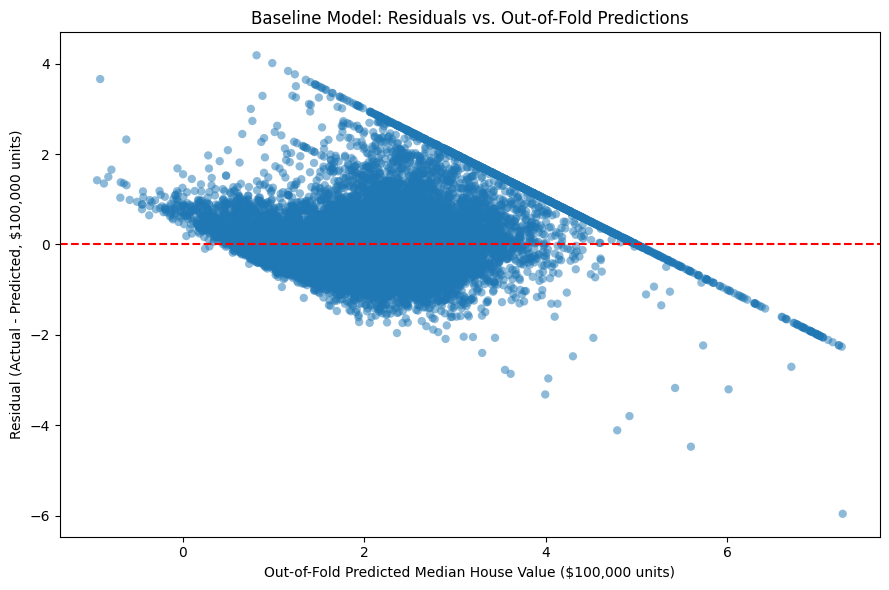

In [130]:

import matplotlib.pyplot as plt

# Calculate out-of-fold residuals
residuals = y_train - y_train_oof_pred

# Plot residuals against out-of-fold predictions
plt.figure(figsize=(9, 6))

plt.scatter(
    y_train_oof_pred,
    residuals,
    alpha=0.5,
    edgecolors="none"
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Out-of-Fold Predicted Median House Value ($100,000 units)")
plt.ylabel("Residual (Actual - Predicted, $100,000 units)")
plt.title("Baseline Model: Residuals vs. Out-of-Fold Predictions")

plt.tight_layout()
plt.show()




### 13.1 Baseline Model Diagnostic Findings

The residual plot helps identify patterns in the baseline
model's out-of-fold prediction errors.

Systematic patterns may indicate that the linear model does
not fully capture the relationships between the features
and the target. Observations near the dataset's upper
target-value cap may also be difficult to predict accurately.

These findings motivate further model evaluation and
comparison. No observations will be removed solely because
they have large residuals.


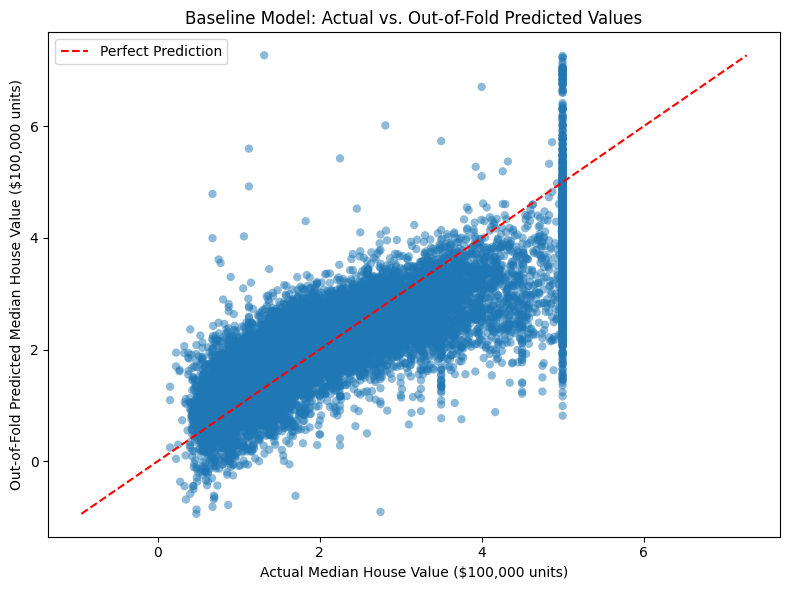

In [131]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_train,
    y_train_oof_pred,
    alpha=0.5,
    edgecolors="none"
)

# Reference line: perfect predictions
lower = min(y_train.min(), y_train_oof_pred.min())
upper = max(y_train.max(), y_train_oof_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Median House Value ($100,000 units)")
plt.ylabel("Out-of-Fold Predicted Median House Value ($100,000 units)")
plt.title("Baseline Model: Actual vs. Out-of-Fold Predicted Values")
plt.legend()

plt.tight_layout()
plt.show()


## 14. Improved Modelling Workflow

### 14.1 Pipeline and Cross-Validation

Use a scikit-learn Pipeline to combine feature standardization and Linear Regression into one workflow.

Evaluate the pipeline using five-fold cross-validation on the training set. Each fold will be used for validation once, while the remaining folds are used for fitting.

The held-out test set will not be used for model selection. Cross-validation results will provide a more reliable basis for comparing candidate regression models.

In [132]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])


In [133]:

from sklearn.model_selection import cross_val_score
import numpy as np

cv_scores = cross_val_score(
    linear_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

cv_rmse = -cv_scores

print("RMSE for each fold:", cv_rmse)
print(f"Mean CV RMSE: {cv_rmse.mean():.4f}")
print(f"Standard deviation: {cv_rmse.std():.4f}")


RMSE for each fold: [0.72115555 0.70872616 0.7214877  0.71266905 0.73859747]
Mean CV RMSE: 0.7205
Standard deviation: 0.0103


### 14.2 Regularized Linear Regression Models

Compare Ridge, Lasso, and Elastic Net regression with the Linear Regression baseline.

- **Ridge:** Applies L2 regularization to shrink coefficient magnitudes.
- **Lasso:** Applies L1 regularization, which can set some coefficients to zero.
- **Elastic Net:** Combines L1 and L2 regularization.

Use pipelines to standardize predictors within each training fold and five-fold cross-validation to compare models using RMSE. Select candidate models using training-set cross-validation results before evaluating the final choice on the held-out test set.

In [134]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet

models = {
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso())
    ]),
    "Elastic Net": Pipeline([
        ("scaler", StandardScaler()),
        ("model", ElasticNet())
    ])
}


In [135]:

from sklearn.model_selection import cross_val_score
import numpy as np

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    rmse_scores = -scores

    print(f"\n{name}")
    print(f"Mean CV RMSE: {rmse_scores.mean():.4f}")
    print(f"Std CV RMSE:  {rmse_scores.std():.4f}")



Ridge
Mean CV RMSE: 0.7205
Std CV RMSE:  0.0103

Lasso
Mean CV RMSE: 1.1562
Std CV RMSE:  0.0128

Elastic Net
Mean CV RMSE: 1.0289
Std CV RMSE:  0.0123


### 14.3 Polynomial Regression

Extend the linear model by generating polynomial and interaction features from the original predictors.

Polynomial Regression can capture nonlinear patterns that ordinary Multiple Linear Regression may miss. However, increasing the number of features can also cause overfitting.

Use a Pipeline to apply polynomial feature generation, standardization, and Linear Regression within each cross-validation fold. Compare the resulting five-fold RMSE against the existing baseline of 0.7205.

In [136]:

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
import numpy as np

poly_pipeline = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

poly_scores = cross_val_score(
    poly_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

poly_rmse = -poly_scores

print("Polynomial Regression — Degree 2")
print("RMSE for each fold:", poly_rmse)
print(f"Mean CV RMSE: {poly_rmse.mean():.4f}")
print(f"Std CV RMSE: {poly_rmse.std():.4f}")


Polynomial Regression — Degree 2
RMSE for each fold: [0.65555749 0.84840895 6.9005711  0.91159897 1.62567749]
Mean CV RMSE: 2.1884
Std CV RMSE: 2.3789


### 14.4 Comparing Polynomial Degrees

Evaluate Polynomial Regression at degrees 1, 2, and 3 using five-fold cross-validation.

Compare the mean RMSE and its standard deviation to assess predictive performance and stability. Polynomial degree will be treated as a hyperparameter rather than assuming that a higher degree produces a better model.

All preprocessing and polynomial feature generation will occur inside the pipeline to prevent information leakage between cross-validation folds.

In [137]:

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
import pandas as pd
import numpy as np

results = []

for degree in [1, 2, 3]:
    poly_pipeline = Pipeline([
        ("poly", PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])

    scores = cross_val_score(
        poly_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    rmse_scores = -scores

    results.append({
        "Degree": degree,
        "Mean CV RMSE": rmse_scores.mean(),
        "Std CV RMSE": rmse_scores.std(),
        "Fold RMSEs": np.round(rmse_scores, 4).tolist()
    })

results_df = pd.DataFrame(results)
results_df


,Degree,Mean CV RMSE,Std CV RMSE,Fold RMSEs
0,1,0.720527,0.010285,"[0.7212, 0.7087, 0.7215, 0.7127, 0.7386]"
1,2,2.188363,2.378933,"[0.6556, 0.8484, 6.9006, 0.9116, 1.6257]"
2,3,297.341539,498.014696,"[0.6222, 4.3729, 1282.8424, 190.7433, 8.1268]"


### 14.4.1 Polynomial Degree Comparison — Findings

Polynomial Regression was evaluated at degrees 1, 2, and 3 using five-fold cross-validation.

- **Degree 1:** Mean CV RMSE of 0.7205, with low fold-to-fold variation.
- **Degree 2:** Mean CV RMSE of 2.1884, with substantial variation across folds.
- **Degree 3:** Mean CV RMSE of 297.3415, with extreme instability.

Increasing polynomial degree did not improve validation performance. Instead, the expanded feature space produced unstable predictions in some folds.

Degree 1 remains the strongest of these three polynomial candidates. Higher-degree ordinary least-squares polynomial models will not be pursued further in this comparison. Regularized models and carefully controlled model selection will be investigated next.

### 14.5 Hyperparameter Tuning of Regularized Regression Models

Tune Ridge, Lasso, and Elastic Net by searching across several values of the regularization parameter `alpha`.

Use five-fold cross-validation and RMSE to select the best parameter for each model. Scaling and model fitting will be handled inside a Pipeline to prevent preprocessing leakage.

The held-out test set will remain reserved for the final evaluation after model selection.

In [138]:

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
import pandas as pd

param_grid = {
    "Ridge": {
        "model": Ridge(),
        "params": {
            "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
        }
    },
    "Lasso": {
        "model": Lasso(max_iter=20000),
        "params": {
            "model__alpha": [0.0001, 0.001, 0.01, 0.1, 1]
        }
    },
    "Elastic Net": {
        "model": ElasticNet(max_iter=20000),
        "params": {
            "model__alpha": [0.0001, 0.001, 0.01, 0.1, 1],
            "model__l1_ratio": [0.2, 0.5, 0.8]
        }
    }
}

tuning_results = []
best_models = {}

for name, config in param_grid.items():
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", config["model"])
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=config["params"],
        scoring="neg_root_mean_squared_error",
        cv=5,
        n_jobs=-1,
        return_train_score=True
    )

    search.fit(X_train, y_train)

    best_index = search.best_index_
    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV RMSE": -search.best_score_,
        "CV RMSE Std": search.cv_results_[
            "std_test_score"
        ][best_index],
        "Best Parameters": search.best_params_
    })

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df.sort_values("Best CV RMSE").reset_index(drop=True)


,Model,Best CV RMSE,CV RMSE Std,Best Parameters
0,Lasso,0.720524,0.010272,{'model__alpha': 0.0001}
1,Elastic Net,0.720524,0.010274,"{'model__alpha': 0.0001, 'model__l1_ratio': 0.8}"
2,Ridge,0.720527,0.010285,{'model__alpha': 0.001}


### 14.6 Final Model Comparison

Compare the baseline Linear Regression model with the tuned Ridge, Lasso, and Elastic Net models using their five-fold cross-validation RMSE.

The purpose is to identify the best-supported candidate based on predictive performance and validation stability. Models with nearly identical scores will be treated as practically equivalent unless further evidence suggests otherwise.

The held-out test set remains reserved for the final evaluation of the selected model.

In [139]:

import pandas as pd
import numpy as np

from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

# Use the same five-fold CV setup and training data
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (Tuned)": Ridge(alpha=0.001),
    "Lasso (Tuned)": Lasso(alpha=0.0001, max_iter=20000),
    "Elastic Net (Tuned)": ElasticNet(
        alpha=0.0001,
        l1_ratio=0.8,
        max_iter=20000
    )
}

comparison_results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    fold_rmse = -cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    comparison_results.append({
        "Model": name,
        "Mean CV RMSE": fold_rmse.mean(),
        "Std CV RMSE": fold_rmse.std()
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    "Mean CV RMSE"
).reset_index(drop=True)

comparison_df.round(6)


,Model,Mean CV RMSE,Std CV RMSE
0,Lasso (Tuned),0.720524,0.010272
1,Elastic Net (Tuned),0.720524,0.010274
2,Linear Regression,0.720527,0.010285
3,Ridge (Tuned),0.720527,0.010285


## 15. Final Model Evaluation

Select Multiple Linear Regression as the final model based on its cross-validation performance and simplicity. Fit the complete pipeline on the full training set and evaluate it on the held-out test set.

The test set is used only for this final evaluation, providing an estimate of how the selected model performs on unseen observations.

In [140]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Fit on all training data
final_model.fit(X_train, y_train)

# Evaluate on the held-out test set
y_test_pred = final_model.predict(X_test)

mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)

print(f"Final Test MAE:  {mae:.4f}")
print(f"Final Test MSE:  {mse:.4f}")
print(f"Final Test RMSE: {rmse:.4f}")
print(f"Final Test R²:   {r2:.4f}")


Final Test MAE:  0.5332
Final Test MSE:  0.5559
Final Test RMSE: 0.7456
Final Test R²:   0.5758


## 15A. Final Visual Analysis

### 15A.1 Cross-Validation Model Performance Comparison

Compare the cross-validation RMSE of the regression models to assess their generalization performance. Lower RMSE indicates better predictive performance.

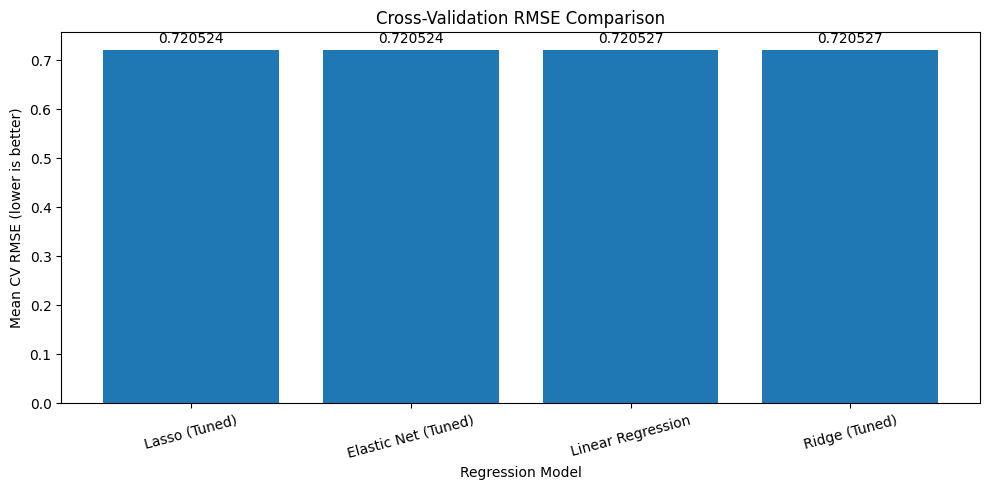

In [141]:

import matplotlib.pyplot as plt

# Use the actual cross-validation results from Section 14.6
plot_df = comparison_df.copy()

plot_df = plot_df.sort_values("Mean CV RMSE")

plt.figure(figsize=(10, 5))

bars = plt.bar(
    plot_df["Model"],
    plot_df["Mean CV RMSE"]
)

plt.title("Cross-Validation RMSE Comparison")
plt.xlabel("Regression Model")
plt.ylabel("Mean CV RMSE (lower is better)")
plt.xticks(rotation=15)
plt.bar_label(bars, fmt="%.6f", padding=3)

plt.tight_layout()
plt.show()


### 15A.2 Actual vs. Predicted Values

This plot compares the actual median house values with the values predicted by the final Linear Regression model. The diagonal reference line represents perfect predictions. Points closer to this line indicate more accurate predictions.

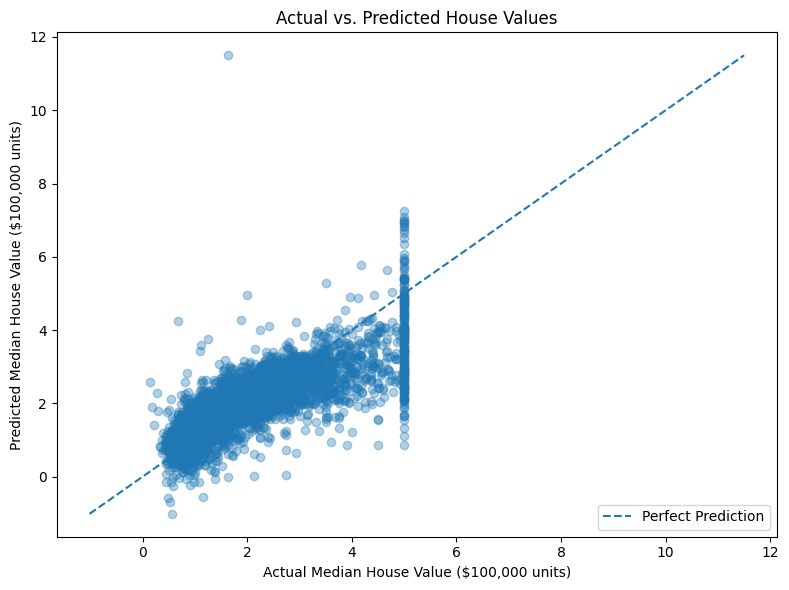

In [142]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.35
)

# Reference line: perfect predictions
min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs. Predicted House Values")
plt.xlabel("Actual Median House Value ($100,000 units)")
plt.ylabel("Predicted Median House Value ($100,000 units)")
plt.legend()
plt.tight_layout()
plt.show()


### 15A.3 Residual Error Distribution

This histogram shows the distribution of residual errors from the final Linear Regression model. Residuals are calculated as actual values minus predicted values. The distribution helps us identify whether errors are centered around zero, skewed, or affected by unusually large prediction errors.

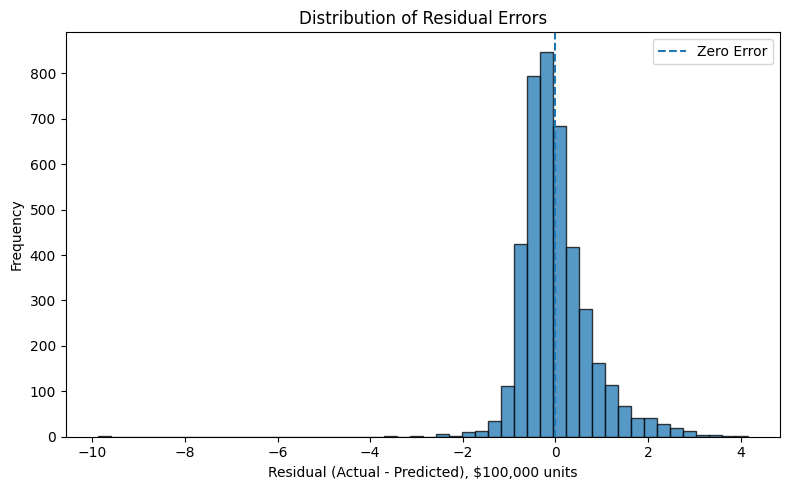

In [143]:

import matplotlib.pyplot as plt

# Residual = actual value - predicted value
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    0,
    linestyle="--",
    label="Zero Error"
)

plt.title("Distribution of Residual Errors")
plt.xlabel("Residual (Actual - Predicted), $100,000 units")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


### 15A.4 Residuals vs. Predicted Values

This plot examines the relationship between predicted median house values and residual errors. A random scatter around the zero line is generally desirable. Visible patterns, curvature, or changing spread may indicate that the model does not capture all relationships in the data or that error variance is not constant.

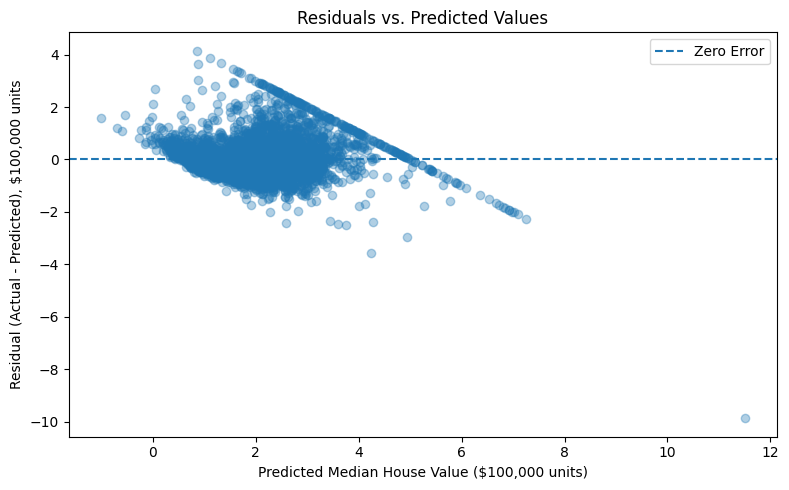

In [144]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_pred,
    residuals,
    alpha=0.35
)

plt.axhline(
    0,
    linestyle="--",
    label="Zero Error"
)

plt.title("Residuals vs. Predicted Values")
plt.xlabel("Predicted Median House Value ($100,000 units)")
plt.ylabel("Residual (Actual - Predicted), $100,000 units")
plt.legend()
plt.tight_layout()
plt.show()


### 15A.5 Cross-Validation Stability

This plot compares the RMSE obtained across the five cross-validation folds for Linear Regression, Ridge, Lasso, and Elastic Net. It helps assess whether model performance is consistent across different data splits. Lower RMSE indicates better performance, while smaller variation across folds indicates greater stability.

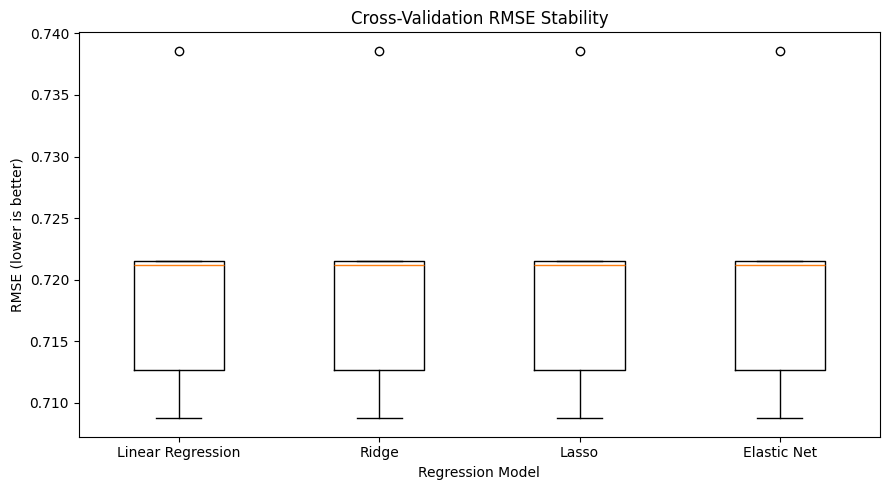

Fold-wise RMSE:
   Linear Regression   Ridge   Lasso  Elastic Net
0             0.7212  0.7212  0.7212       0.7212
1             0.7087  0.7087  0.7087       0.7087
2             0.7215  0.7215  0.7215       0.7215
3             0.7127  0.7127  0.7127       0.7127
4             0.7386  0.7386  0.7386       0.7386


In [145]:

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

# Tuned model configurations from our earlier GridSearchCV results
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=0.001),
    "Lasso": Lasso(alpha=0.0001, max_iter=20000),
    "Elastic Net": ElasticNet(
        alpha=0.0001,
        l1_ratio=0.8,
        max_iter=20000
    )
}

fold_results = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    scores = -cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    fold_results[name] = scores

fold_df = pd.DataFrame(fold_results)

plt.figure(figsize=(9, 5))

plt.boxplot(
    [fold_df[col] for col in fold_df.columns],
    tick_labels=fold_df.columns
)

plt.title("Cross-Validation RMSE Stability")
plt.xlabel("Regression Model")
plt.ylabel("RMSE (lower is better)")
plt.tight_layout()
plt.show()

print("Fold-wise RMSE:")
print(fold_df.round(4))


### 15A.6 Feature Coefficient Analysis

This horizontal bar chart displays the coefficients learned by the final Multiple Linear Regression model. Since the input features are standardized within the pipeline, the coefficient magnitudes indicate how the prediction changes with a one-standard-deviation increase in each feature, holding the other features constant. Positive coefficients indicate positive associations, while negative coefficients indicate negative associations. These relationships should not be interpreted as causal effects.

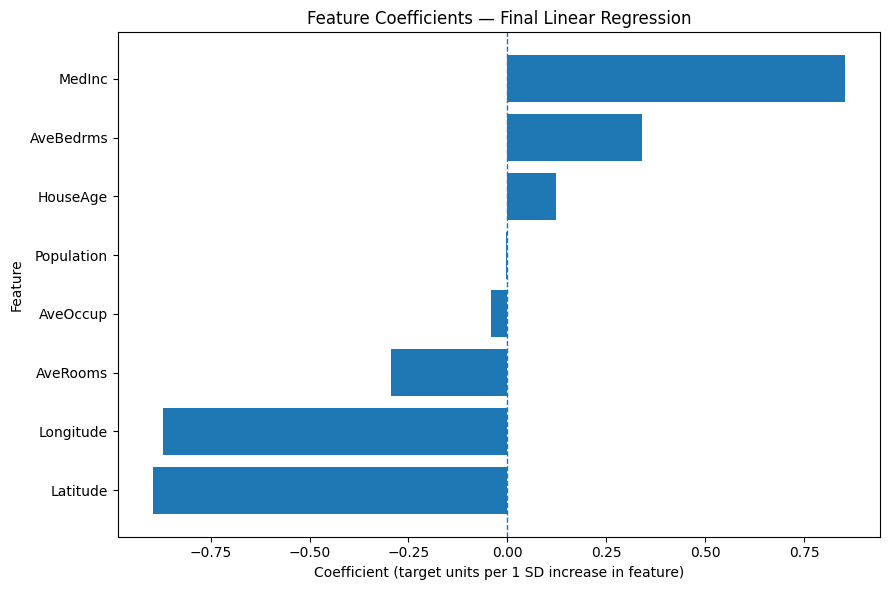

Feature coefficients:
Latitude     -0.8969
Longitude    -0.8698
AveRooms     -0.2944
AveOccup     -0.0408
Population   -0.0023
HouseAge      0.1225
AveBedrms     0.3393
MedInc        0.8544
dtype: float64


In [146]:

import matplotlib.pyplot as plt
import pandas as pd

# Extract coefficients from the fitted final pipeline
coefficients = pd.Series(
    final_model.named_steps["model"].coef_,
    index=X_train.columns
)

# Sort coefficients for a clear horizontal bar chart
coefficients = coefficients.sort_values()

plt.figure(figsize=(9, 6))

bars = plt.barh(
    coefficients.index,
    coefficients.values
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.title("Feature Coefficients — Final Linear Regression")
plt.xlabel("Coefficient (target units per 1 SD increase in feature)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Feature coefficients:")
print(coefficients.round(4))


### 15A.7 Polynomial Model Complexity

This plot compares the cross-validation RMSE of polynomial regression models with degrees 1, 2, and 3. It illustrates how increasing model complexity does not necessarily improve generalization performance. A lower RMSE indicates better predictive performance, while large errors and instability across folds may indicate an unsuitable model configuration.

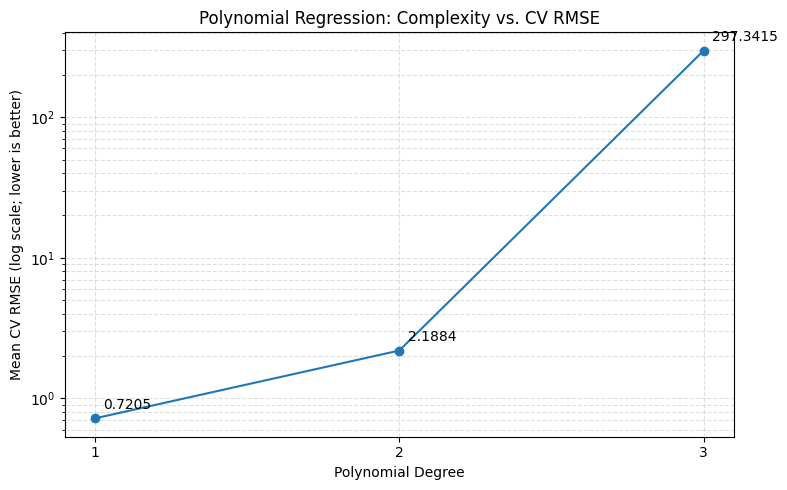

In [147]:

# Use the actual results from Section 14.4
plot_df = results_df.sort_values("Degree")

degrees = plot_df["Degree"]
mean_cv_rmse = plot_df["Mean CV RMSE"]

plt.figure(figsize=(8, 5))

plt.plot(
    degrees,
    mean_cv_rmse,
    marker="o"
)

plt.yscale("log")

for degree, score in zip(degrees, mean_cv_rmse):
    plt.annotate(
        f"{score:.4f}",
        (degree, score),
        xytext=(6, 7),
        textcoords="offset points"
    )

plt.title("Polynomial Regression: Complexity vs. CV RMSE")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean CV RMSE (log scale; lower is better)")
plt.xticks(degrees)
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


### 15A.8 Visual Analysis — Key Findings

1. **Model comparison:** Linear Regression, Ridge, Lasso, and Elastic Net achieved nearly identical cross-validation RMSE values. Regularization provided no meaningful improvement in this experiment.

2. **Actual vs. predicted values:** Predictions were concentrated toward the middle of the target range, and the model struggled with some high-value observations, including values affected by the dataset's upper target cap.

3. **Residual distribution:** Most residuals were concentrated around zero, with a negative tail indicating substantial overprediction for a small number of observations.

4. **Residual diagnostics:** Patterns in the residuals-versus-predicted plot and an extreme observation suggest that the linear model does not capture all relationships in the dataset.

5. **Cross-validation stability:** The four linear-model approaches showed similar fold-wise performance, with no substantial improvement in predictive performance from regularization.

6. **Feature coefficients:** Median income had the strongest positive coefficient, while latitude and longitude had negative coefficients in the fitted model. These coefficients represent conditional linear associations and should not be interpreted as causal effects.

7. **Polynomial complexity:** Degree 2 and degree 3 polynomial regression performed substantially worse on average and showed instability across folds. Increasing model complexity did not improve generalization in this experiment.

**Overall conclusion:** Multiple Linear Regression was retained as the final model because it provided a simple baseline with competitive cross-validation performance. Its final predictive performance was then assessed using the held-out test set, which was not used for model selection.

## 16. Conclusion

### Project Overview

This project developed a regression workflow to predict district-level median house values using the California Housing dataset. It covered data inspection, exploratory data analysis, preprocessing, feature scaling, baseline modelling, residual analysis, cross-validation, model comparison, and hyperparameter tuning.

### Final Model Selection

Multiple Linear Regression was selected as the final model because it achieved competitive cross-validation performance while remaining simple and interpretable. Tuned Ridge, Lasso, and Elastic Net produced nearly identical cross-validation RMSE values, so regularization did not provide a meaningful improvement in this experiment.

### Final Test Performance

The selected model was evaluated on the held-out test set.

- **Mean Absolute Error (MAE):** 0.5332
- **Mean Squared Error (MSE):** 0.5559
- **Root Mean Squared Error (RMSE):** 0.7456
- **R² Score:** 0.5758

The model explained approximately 57.6% of the variation in district-level median house values in the test set. Since the target is expressed in units of $100,000, the MAE corresponds to approximately $53,320 and the RMSE to approximately $74,560.

### Key Findings

- Median income had the strongest positive coefficient in the final linear model.
- The actual-versus-predicted and residual plots revealed prediction errors, particularly for some high-value observations.
- Cross-validation showed similar performance among the four linear-model approaches.
- Polynomial regression with degrees 2 and 3 performed substantially worse and showed considerable instability across folds.

### Limitations

The model captures only linear relationships between the original features and the target. It does not explain all the variation in house values, and the dataset's upper-capped target values limit interpretation for high-value districts. The coefficients describe associations within this model and should not be interpreted as causal effects.

### Future Improvements

Future work could investigate tree-based regression models, nonlinear feature relationships, additional feature engineering, and more systematic hyperparameter tuning. Any new models should be compared using cross-validation, with the held-out test set reserved for final evaluation.

### Learning Outcomes

This project strengthened my practical understanding of regression modelling, preprocessing pipelines, regularization, cross-validation, hyperparameter tuning, evaluation metrics, residual diagnostics, and communicating analytical findings through visualisations.

**Final takeaway:** A simpler model can be a sensible choice when more complex or regularized alternatives do not provide meaningful improvements. Reliable model selection requires careful validation, appropriate metrics, and an honest assessment of limitations.